# HW#5 -- Part III: Summarization by Prompting using LLM Decoder Models

**Name:** Asad Khan
**Course:** CSC 583 -- Natural Language Processing, Fall 2026
**Assignment:** HW#5, Part III
**Collaborators:** None. GenAI disclosure: Claude (Anthropic) was used as a coding assistant.

The starter uses Anthropic Claude as an example; the assignment allows any SOTA LLM. I used
**OpenAI's API**: `gpt-5.4-mini` generates the summaries, and the stronger `gpt-5.5` acts as an
independent judge in the optional LLM-as-a-judge section. Sections 1 and 3 are adjusted to match.

## 0. Setup

Run locally rather than on Colab. The API key is read from a git-ignored `.env` file one folder
up (the local equivalent of a Colab Secret); it is never hard-coded or printed.

In [1]:
# Already installed in the local uv environment (see NLP/pyproject.toml)
# !pip install -q openai datasets python-dotenv

In [2]:
import os
thisdir = os.getcwd()   # local: the HW5 folder (on Colab this was a Drive folder)
os.chdir(thisdir)

In [3]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import json, re, time, hashlib, textwrap
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv("../.env")             # sets OPENAI_API_KEY in the environment
client = OpenAI()                  # picks the key up from the environment
print("API key loaded:", bool(os.environ.get("OPENAI_API_KEY")))

MODEL = "gpt-5.4-mini"             # summarizer
JUDGE_MODEL = "gpt-5.5"            # separate, stronger model for LLM-as-a-judge

API key loaded: True


## 1. Reload the same two SAMSum test examples used in Part II

In [4]:
from datasets import load_dataset

samsum = load_dataset("knkarthick/samsum")
test = samsum["test"]

example_idx = [10, 50]   # same indices as Part II

examples = [{"idx": i, "dialogue": test[i]["dialogue"], "reference": test[i]["summary"]} for i in example_idx]

# The Part II outputs for the same dialogues, to compare against
part2 = pd.read_csv("part2_test_predictions.csv")
for ex in examples:
    ex["t5_original"] = part2.loc[ex["idx"], "original"]
    ex["t5_finetuned"] = part2.loc[ex["idx"], "fine_tuned"]
    print(f"--- test[{ex['idx']}] ---\n{ex['dialogue']}\nREFERENCE: {ex['reference']}\n")

--- test[10] ---
Wanda: Let's make a party!
Gina: Why?
Wanda: beacuse. I want some fun!
Gina: ok, what do u need?
Wanda: 1st I need too make a list
Gina: noted and then?
Wanda: well, could u take yours father car and go do groceries with me?
Gina: don't know if he'll agree
Wanda: I know, but u can ask :)
Gina: I'll try but theres no promisess
Wanda: I know, u r the best!
Gina: When u wanna go
Wanda: Friday?
Gina: ok, I'll ask
REFERENCE: Wanda wants to throw a party. She asks Gina to borrow her father's car and go do groceries together. They set the date for Friday. 

--- test[50] ---
Nick: You look absolutely gorgeous and have a lovely smile. 
Nick: Would love to get to know you a bit more. How about we meet up for a drink sometime?
Jane: Hmmm... You're shooting a bit above your range aren't you?
Nick: Why would you think that hon?
Jane: Because I'm not that desperate.
Nick: That was a bit below the belt.
Nick: You're nice but you're not THAT hot.
Jane: Oh is your poor little dick shri

## 2. Hand-crafted prompts (prompt-engineering)

Four prompts, each changing one thing relative to the previous one:

1. **`zero_shot`** -- the Part II `"summarize: "` prefix spelled out as a plain instruction. No
   guidance on length or style, so it shows the model's default notion of a "summary".
2. **`constrained`** -- a system-role prompt that sets a persona (a note-taker writing the one-line
   gist of a chat) and spells out the SAMSum house style I observed in the reference summaries:
   third person, refer to people by name, one or two short sentences, keep only the outcome
   (who will do what, when), and **never add information that is not in the chat**.
3. **`few_shot`** -- no rules at all; instead three dialogue -> summary pairs from the SAMSum
   *training* split are sent as earlier chat turns, so the model has to infer the style by
   in-context learning.
4. **`extract_then_write`** -- a structured prompt: first list the participants, the topic, and
   any decision/plan with its time, then write the summary from those notes only, returning JSON.
   The idea is that making the model ground itself in explicit facts first should reduce
   hallucination and missed details.

In [5]:
PROMPT_1 = """Summarize the following conversation.

{dialogue}"""

SYSTEM_PROMPT_2 = """You are a meticulous note-taker. People paste a messenger chat and you write the gist \
that a colleague would read in a notification preview."""

PROMPT_2 = """Write a summary of the chat below.

Rules:
- One or two short sentences, at most 30 words in total.
- Third person; refer to the participants by their names (never "I", "you", "the user").
- Keep only what matters: the outcome, decision or plan (who will do what, and when, if stated).
- Do not add any detail, motive or emotion that is not explicitly in the chat.
- Plain text only: no bullet points, no quotation marks, no preamble.

Chat:
{dialogue}"""

# Few-shot: three short dialogues from the TRAIN split (never from test), chosen by a fixed rule
def n_words(s):
    return len((s or "").split())
shot_pool = [ex for ex in samsum["train"] if 30 <= n_words(ex["dialogue"]) <= 70][:3]
FEW_SHOT_EXAMPLES = [(ex["dialogue"], ex["summary"]) for ex in shot_pool]
FEW_SHOT_INSTRUCTION = "Summarize the conversation."

SYSTEM_PROMPT_4 = "You summarize messenger conversations accurately. You only state facts present in the conversation."

PROMPT_4 = """Read the chat below and work in two steps.

Step 1 - notes: list (a) the participants, (b) the main topic, (c) any decision, plan or request, \
with who is responsible and when, exactly as stated in the chat.
Step 2 - summary: using ONLY your notes, write a one- or two-sentence third-person summary that \
names the participants.

Return JSON with the keys "participants", "topic", "decision_or_plan" and "summary".

Chat:
{dialogue}"""

for d, s in FEW_SHOT_EXAMPLES:
    print(f"[few-shot example]\n{d}\n=> {s}\n")

[few-shot example]
Noah: When and where are we meeting? :)
Madison: I thought you were busy...?
Noah: Yeah, I WAS. I quit my job. 
Madison: No way! :o :o :o Why? I thought you liked it...?
Noah: Well, I used to, until my boss turned into a complete cock... Long story.
=> Noah wants to meet, he quit his job, because his boss was a dick.

[few-shot example]
Lucas: Hey! How was your day?
Demi: Hey there! 
Demi: It was pretty fine, actually, thank you!
Demi: I just got promoted! :D
Lucas: Whoa! Great news!
Lucas: Congratulations!
Lucas: Such a success has to be celebrated.
Demi: I agree! :D
Demi: Tonight at Death & Co.?
Lucas: Sure!
Lucas: See you there at 10pm?
Demi: Yeah! See you there! :D
=> Demi got promoted. She will celebrate that with Lucas at Death & Co at 10 pm.

[few-shot example]
Tina: I'd only like to remind you that you owe me 50 bucks
Lucy: Of course, I know.
Lucy: I've already transferred the money but it's Sunday today so you'll have it in your bank account tomorrow
Tina: T

## 3. Call the LLM with each prompt, for each example

`build_messages` turns a prompt choice into the actual chat messages; `summarize_with_llm` sends
them through the OpenAI Responses API. Reasoning effort is set to `"none"` (no hidden thinking) for
all four prompts so they are compared on the prompt alone. Responses are cached on disk, so
re-running the notebook does not re-bill the API.

In [6]:
CACHE_PATH = "part3_llm_cache.json"
cache = json.load(open(CACHE_PATH)) if os.path.exists(CACHE_PATH) else {}

def build_messages(dialogue, prompt_name):
    if prompt_name == "zero_shot":
        return [{"role": "user", "content": PROMPT_1.format(dialogue=dialogue)}]
    if prompt_name == "constrained":
        return [{"role": "system", "content": SYSTEM_PROMPT_2},
                {"role": "user", "content": PROMPT_2.format(dialogue=dialogue)}]
    if prompt_name == "few_shot":
        msgs = []
        for d, s in FEW_SHOT_EXAMPLES:
            msgs += [{"role": "user", "content": f"{FEW_SHOT_INSTRUCTION}\n\n{d}"},
                     {"role": "assistant", "content": s}]
        return msgs + [{"role": "user", "content": f"{FEW_SHOT_INSTRUCTION}\n\n{dialogue}"}]
    if prompt_name == "extract_then_write":
        return [{"role": "system", "content": SYSTEM_PROMPT_4},
                {"role": "user", "content": PROMPT_4.format(dialogue=dialogue)}]
    raise ValueError(prompt_name)

def call_llm(messages, model=MODEL, effort="none", json_mode=False):
    key = hashlib.sha256(json.dumps([model, effort, json_mode, messages]).encode()).hexdigest()
    if key in cache:
        return cache[key]
    kwargs = {"text": {"format": {"type": "json_object"}}} if json_mode else {}
    for attempt in range(5):
        try:
            r = client.responses.create(model=model, input=messages, reasoning={"effort": effort}, **kwargs)
            break
        except Exception as e:   # rate limits / transient errors
            if attempt == 4:
                raise
            time.sleep(2 ** attempt)
    out = {"text": r.output_text.strip(), "input_tokens": r.usage.input_tokens,
           "output_tokens": r.usage.output_tokens,
           "reasoning_tokens": r.usage.output_tokens_details.reasoning_tokens}
    cache[key] = out
    return out

def summarize_with_llm(dialogue, prompt_name, effort="none", return_meta=False):
    out = call_llm(build_messages(dialogue, prompt_name), effort=effort,
                   json_mode=(prompt_name == "extract_then_write"))
    text = out["text"]
    if prompt_name == "extract_then_write":
        text = json.loads(text)["summary"].strip()
    return (text, out) if return_meta else text

PROMPTS = ["zero_shot", "constrained", "few_shot", "extract_then_write"]

results = []
for ex in examples:
    row = dict(ex)
    for p in PROMPTS:
        row[f"{p}_summary"] = summarize_with_llm(ex["dialogue"], p)
    results.append(row)
json.dump(cache, open(CACHE_PATH, "w"), indent=1)

for row in results:
    print("=" * 110)
    print(f"test[{row['idx']}]\nDIALOGUE:\n{row['dialogue']}\n")
    for name, text in [("REFERENCE", row["reference"]), ("T5 original (Part II)", row["t5_original"]),
                       ("T5 fine-tuned (Part II)", row["t5_finetuned"])] + \
                      [(f"LLM / {p}", row[f"{p}_summary"]) for p in PROMPTS]:
        print(f"{name}:\n" + textwrap.fill(text, 105, initial_indent="    ", subsequent_indent="    ") + "\n")

test[10]
DIALOGUE:
Wanda: Let's make a party!
Gina: Why?
Wanda: beacuse. I want some fun!
Gina: ok, what do u need?
Wanda: 1st I need too make a list
Gina: noted and then?
Wanda: well, could u take yours father car and go do groceries with me?
Gina: don't know if he'll agree
Wanda: I know, but u can ask :)
Gina: I'll try but theres no promisess
Wanda: I know, u r the best!
Gina: When u wanna go
Wanda: Friday?
Gina: ok, I'll ask

REFERENCE:
    Wanda wants to throw a party. She asks Gina to borrow her father's car and go do groceries together.
    They set the date for Friday.

T5 original (Part II):
    Gina: ok, what do u need? Wanda: I know, u r the best!

T5 fine-tuned (Part II):
    Gina and Wanda will go to a party on Friday.

LLM / zero_shot:
    Wanda wants to throw a party for fun and asks Gina for help. First, Wanda says she needs to make a
    list, then asks Gina to see if she can borrow her father’s car so they can go grocery shopping
    together. Gina is unsure her father

In [7]:
# What the structured prompt's intermediate notes looked like
for ex in examples:
    _, meta = summarize_with_llm(ex["dialogue"], "extract_then_write", return_meta=True)
    print(f"test[{ex['idx']}]:", json.dumps(json.loads(meta["text"]), indent=2), "\n")

test[10]: {
  "participants": [
    "Wanda",
    "Gina"
  ],
  "topic": "Making a party and planning groceries for it.",
  "decision_or_plan": [
    {
      "request": "Wanda said she first needs to make a list."
    },
    {
      "request": "Wanda asked Gina to take her father's car and go do groceries with her.",
      "responsible": "Gina",
      "when": "Friday"
    },
    {
      "request": "Gina said she'll ask her father, but there are no promises."
    }
  ],
  "summary": "Wanda and Gina talked about making a party and planning the preparations. Wanda said she needs to make a list and asked Gina to ask her father about using his car to go grocery shopping together on Friday, and Gina said she would ask but made no promises."
} 

test[50]: {
  "participants": [
    "Nick",
    "Jane"
  ],
  "topic": "They exchange insults after Nick asks Jane to meet for a drink and Jane responds dismissively.",
  "decision_or_plan": [
    {
      "who": "Nick",
      "request": "How about we m

### 3b. Beyond two examples: the same prompts on 200 test dialogues

Two examples are too few to say much, so I also ran every prompt on the first 200 SAMSum test
dialogues and scored them with the same ROUGE / BERTScore / GPT-2 perplexity metrics as Part II,
next to the Part II fine-tuned T5 on exactly the same 200 dialogues.

In [8]:
import torch
from evaluate import load as load_metric
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
rouge = load_metric("rouge")
bertscore = load_metric("bertscore")
gpt2_tokenizer = AutoTokenizer.from_pretrained("gpt2")
gpt2_tokenizer.pad_token = gpt2_tokenizer.eos_token
gpt2_model = AutoModelForCausalLM.from_pretrained("gpt2").to(device).eval()

def compute_mean_perplexity(texts, max_length=1024):
    perplexities = []
    with torch.no_grad():
        for text in texts:
            input_ids = gpt2_tokenizer(text, return_tensors="pt", truncation=True, max_length=max_length)["input_ids"].to(device)
            if input_ids.size(1) < 2:
                continue
            perplexities.append(torch.exp(gpt2_model(input_ids, labels=input_ids).loss).item())
    return float(np.mean(perplexities))

def evaluate_summaries(predictions, references):
    preds = [p if p.strip() else "." for p in predictions]
    r = rouge.compute(predictions=preds, references=references)
    bs = bertscore.compute(predictions=preds, references=references, lang="en")
    return {"rouge1": r["rouge1"], "rouge2": r["rouge2"], "rougeL": r["rougeL"],
            "mean_perplexity": compute_mean_perplexity(preds),
            "bertscore_precision": float(np.mean(bs["precision"])), "bertscore_recall": float(np.mean(bs["recall"])),
            "bertscore_f1": float(np.mean(bs["f1"])), "mean_words": float(np.mean([len(p.split()) for p in preds]))}

N_EVAL = 200
eval_dialogues = list(test["dialogue"][:N_EVAL])
eval_refs = list(test["summary"][:N_EVAL])

llm_preds = {}
with ThreadPoolExecutor(max_workers=8) as pool:
    for p in PROMPTS:
        llm_preds[p] = list(pool.map(lambda d: summarize_with_llm(d, p), eval_dialogues))
json.dump(cache, open(CACHE_PATH, "w"), indent=1)

scale_metrics = {"T5 original (Part II)": evaluate_summaries(list(part2["original"][:N_EVAL].fillna("")), eval_refs),
                 "T5 fine-tuned (Part II)": evaluate_summaries(list(part2["fine_tuned"][:N_EVAL].fillna("")), eval_refs)}
for p in PROMPTS:
    scale_metrics[f"{MODEL} / {p}"] = evaluate_summaries(llm_preds[p], eval_refs)
scale_metrics["reference (human)"] = {"mean_perplexity": compute_mean_perplexity(eval_refs),
                                      "mean_words": float(np.mean([len(r.split()) for r in eval_refs]))}
scale_df = pd.DataFrame(scale_metrics).T
scale_df.round(4)

,rouge1,rouge2,rougeL,mean_perplexity,bertscore_precision,bertscore_recall,bertscore_f1,mean_words
T5 original (Part II),0.2566,0.0605,0.2016,148.6729,0.8541,0.8794,0.8664,21.265
T5 fine-tuned (Part II),0.4513,0.2162,0.3759,156.4702,0.9208,0.9127,0.9165,16.380
gpt-5.4-mini / zero_shot,0.3154,0.1068,0.2394,58.4393,0.8678,0.9185,0.8923,60.985
gpt-5.4-mini / constrained,0.4488,0.1809,0.3524,146.7723,0.9099,0.9190,0.9143,20.035
gpt-5.4-mini / few_shot,0.4117,0.1562,0.3167,86.1179,0.8935,0.9243,0.9085,33.480
gpt-5.4-mini / extract_then_write,0.3867,0.1486,0.3032,55.3297,0.8917,0.9230,0.9069,36.515
reference (human),NaN,NaN,NaN,134.5986,NaN,NaN,NaN,19.605


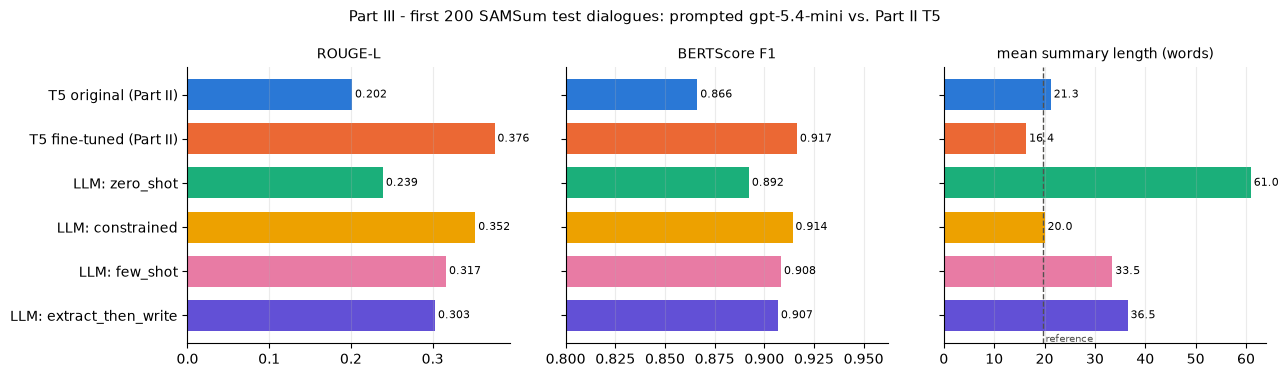

In [9]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
systems = [s for s in scale_df.index if s != "reference (human)"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
for ax, m in zip(axes, ["rougeL", "bertscore_f1", "mean_words"]):
    vals = scale_df.loc[systems, m]
    bars = ax.barh(range(len(systems)), vals, color=COLORS[:len(systems)], height=0.7)
    ax.bar_label(bars, fmt="%.3f" if m != "mean_words" else "%.1f", fontsize=8, padding=2)
    ax.set_yticks(range(len(systems)), [s.replace(f"{MODEL} / ", "LLM: ") for s in systems] if ax is axes[0] else [""] * len(systems))
    ax.invert_yaxis()
    ax.set_title({"rougeL": "ROUGE-L", "bertscore_f1": "BERTScore F1", "mean_words": "mean summary length (words)"}[m], fontsize=10)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.25)
axes[1].set_xlim(left=0.8)
axes[2].axvline(scale_df.loc["reference (human)", "mean_words"], color="#52514e", ls="--", lw=1)
axes[2].text(scale_df.loc["reference (human)", "mean_words"], len(systems) - 0.4, " reference", fontsize=7, color="#52514e")
fig.suptitle(f"Part III - first {N_EVAL} SAMSum test dialogues: prompted {MODEL} vs. Part II T5", fontsize=11)
fig.tight_layout()
fig.savefig("part3_prompt_metrics.png", dpi=200, bbox_inches="tight")
plt.show()

### 3c. (Optional) Does a reasoning ("thinking") setting help?

Same model, same `constrained` prompt, but with reasoning effort `"high"` instead of `"none"`, on
the same 200 dialogues -- comparing quality against the extra tokens it costs.

In [10]:
with ThreadPoolExecutor(max_workers=8) as pool:
    high = list(pool.map(lambda d: summarize_with_llm(d, "constrained", effort="high", return_meta=True), eval_dialogues))
    none = list(pool.map(lambda d: summarize_with_llm(d, "constrained", effort="none", return_meta=True), eval_dialogues))
json.dump(cache, open(CACHE_PATH, "w"), indent=1)

reasoning_cmp = pd.DataFrame({
    "effort=none": {**evaluate_summaries([t for t, _ in none], eval_refs),
                    "mean_output_tokens": np.mean([m["output_tokens"] for _, m in none]),
                    "mean_reasoning_tokens": np.mean([m["reasoning_tokens"] for _, m in none])},
    "effort=high": {**evaluate_summaries([t for t, _ in high], eval_refs),
                    "mean_output_tokens": np.mean([m["output_tokens"] for _, m in high]),
                    "mean_reasoning_tokens": np.mean([m["reasoning_tokens"] for _, m in high])},
})
reasoning_high = {ex["idx"]: summarize_with_llm(ex["dialogue"], "constrained", effort="high") for ex in examples}
for i, s in reasoning_high.items():
    print(f"test[{i}] constrained, effort=high: {s}")
reasoning_cmp.round(4)

test[10] constrained, effort=high: Wanda plans a party and will make a list. Gina will ask her father about borrowing his car for Friday groceries.
test[50] constrained, effort=high: Nick asked Jane to meet for a drink, but Jane rejected him and the chat ended with them trading insults.


,effort=none,effort=high
rouge1,0.4488,0.4630
rouge2,0.1809,0.1885
rougeL,0.3524,0.3615
mean_perplexity,146.7723,166.7096
bertscore_precision,0.9099,0.9134
bertscore_recall,0.9190,0.9201
bertscore_f1,0.9143,0.9166
mean_words,20.0350,18.6900
mean_output_tokens,28.1850,236.4350
mean_reasoning_tokens,0.0000,207.5600


## 4. Save results (for the write-up)

In [11]:
pd.DataFrame(results).to_csv("part3_results.csv", index=False)
scale_df.round(4).to_csv("part3_prompt_metrics.csv")
reasoning_cmp.round(4).to_csv("part3_reasoning_comparison.csv")
pd.DataFrame({"idx": range(N_EVAL), "reference": eval_refs, **llm_preds}).to_csv("part3_llm_predictions_200.csv", index=False)
print("Saved part3_results.csv, part3_prompt_metrics.csv, part3_reasoning_comparison.csv, part3_llm_predictions_200.csv")

Saved part3_results.csv, part3_prompt_metrics.csv, part3_reasoning_comparison.csv, part3_llm_predictions_200.csv


## 5. (Optional, extra credit) LLM-as-a-judge

A separate, stronger model (`gpt-5.5`, with reasoning) sees the dialogue and the human reference,
then scores each candidate summary for **faithfulness** (is everything supported by the chat?),
**coverage** (are the key points there?) and **coherence** (1-5 each) with a one-sentence
justification. The candidates are shown under anonymous letters in a shuffled order, so the judge
does not know which system wrote which summary (and the reference itself is also scored, as a
sanity check).

In [12]:
JUDGE_SYSTEM = "You are a strict, careful evaluator of dialogue summaries. You output JSON only."

JUDGE_PROMPT = """Below is a messenger dialogue, a human-written reference summary, and several candidate summaries \
labelled with letters. Score EACH candidate on three 1-5 scales:
- faithfulness: 5 = every statement is supported by the dialogue; 1 = major invented or wrong facts.
- coverage: 5 = contains all key points of the dialogue (who, what, decisions, times); 1 = misses the point.
- coherence: 5 = fluent, well-formed, easy to read on its own; 1 = garbled or confusing.
Judge against the DIALOGUE first; the reference is only a guide to what matters.

Return JSON: {{"scores": {{"<letter>": {{"faithfulness": int, "coverage": int, "coherence": int, "justification": "<one sentence>"}}, ...}}}}

DIALOGUE:
{dialogue}

REFERENCE SUMMARY:
{reference}

CANDIDATES:
{candidates}"""

def judge_summary(row, systems, seed):
    rng = np.random.default_rng(seed)
    order = list(rng.permutation(systems))
    letters = [chr(ord("A") + k) for k in range(len(order))]
    cand_text = "\n".join(f"{L}: {row[s]}" for L, s in zip(letters, order))
    msgs = [{"role": "system", "content": JUDGE_SYSTEM},
            {"role": "user", "content": JUDGE_PROMPT.format(dialogue=row["dialogue"], reference=row["reference"],
                                                            candidates=cand_text)}]
    out = call_llm(msgs, model=JUDGE_MODEL, effort="medium", json_mode=True)
    scores = json.loads(out["text"])["scores"]
    return {s: scores[L] for L, s in zip(letters, order)}

judged_systems = ["reference", "t5_original", "t5_finetuned"] + [f"{p}_summary" for p in PROMPTS]
judge_rows = []
for row in results:
    for system, sc in judge_summary(row, judged_systems, seed=row["idx"]).items():
        judge_rows.append({"idx": row["idx"], "system": system.replace("_summary", ""), **sc})
json.dump(cache, open(CACHE_PATH, "w"), indent=1)

judge_df = pd.DataFrame(judge_rows)
judge_df.to_csv("part3_llm_judge.csv", index=False)
pd.set_option("display.max_colwidth", 200)
judge_df

,idx,system,faithfulness,coverage,coherence,justification
0,10,zero_shot,5,5,5,"Fully supported by the dialogue and covers the party, list, car request, grocery shopping, Gina's uncertainty, and Friday timing clearly."
1,10,constrained,5,4,5,"Accurately states the main plan and Friday car/grocery request, but omits Gina's uncertainty and no-promises caveat."
2,10,t5_original,5,1,1,"The quoted lines are from the dialogue, but they do not summarize the situation and are confusing on their own."
3,10,t5_finetuned,2,1,4,It incorrectly says they will go to a party on Friday rather than plan a party and potentially shop for groceries on Friday.
4,10,extract_then_write,5,5,5,"Accurately and clearly captures the party planning, list, request to ask about the car, grocery shopping together, Friday timing, and Gina's no-promises response."
5,10,few_shot,5,5,5,"Faithfully covers Wanda's party plan, list and groceries, the request involving Gina's father's car, Friday timing, and Gina's uncertainty."
6,10,reference,5,4,5,"Accurately captures the core events and Friday timing, but leaves out Wanda's list and Gina's uncertainty about whether her father will agree."
7,50,t5_finetuned,1,1,5,It directly contradicts the dialogue because Jane rejects the drink invitation rather than agreeing to meet.
8,50,constrained,3,3,4,It captures the rejected drink invitation but incorrectly says both told each other to forget it and omits the insulting escalation.
9,50,zero_shot,5,5,5,"It accurately summarizes the invitation, rejection, defensive withdrawal, and escalation into mutual insults."


In [13]:
judge_df.pivot_table(index="system", columns="idx", values=["faithfulness", "coverage", "coherence"]).reindex(
    [s.replace("_summary", "") for s in judged_systems])

coherence      coverage      faithfulness     
idx                       10   50       10   50           10   50
system                                                           
reference                5.0  5.0      4.0  4.0          5.0  5.0
t5_original              1.0  2.0      1.0  1.0          5.0  1.0
t5_finetuned             4.0  5.0      1.0  1.0          2.0  1.0
zero_shot                5.0  5.0      5.0  5.0          5.0  5.0
constrained              5.0  4.0      4.0  3.0          5.0  3.0
few_shot                 5.0  5.0      5.0  4.0          5.0  5.0
extract_then_write       5.0  5.0      5.0  4.0          5.0  5.0